# Task 3 - Cross-dataset generalisation: train on KDEF test on FER2013
## Written by task 2
### This notebook addresses Task 3: evaluating how well a model trained on one dataset (KDEF) generalizes to another dataset (FER2013). The key challenge is "domain shift" - the differences in image acquisition, preprocessing, and style between the two datasets.

In [4]:
import json, time, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from src.preprocess import preprocess_kdef_image
from src.features import (EMOTIONS, KDEF_TO_FER, to_fer_scale, fer_pixels_to_images,
                          hog_features, landmark_features, pixel_features)

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42 # random seed for reproducibility
DATA = Path("data"); RESULTS = Path("results")
FIGS = Path("figures/task3"); FIGS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(exist_ok=True)
SELECT_BY = "cv_macro_f1" # Cross-validation macro-F1 to select the best configu from task 2.

### How "best configuration from task 2" is decided:
### "cv_macro_f1" = subject-grouped cross-validation on the KDEF training subjects
### "macro_f1"    = macro-F1 on the 14 KDEF test subjects


# 1. Best Configuration from task 2
### We load  the results from the KDEF study (Task 2) and identify the best-performing model.
### The best model is chosen based on the cross-validation macro-F1 score, which is a robust
### metric that accounts for class imbalance and is computed on training subjects only.

In [5]:
k2 = pd.read_csv(RESULTS / "task2_kdef_results.csv")
# Selecting only the relevant columns for display (safely handles if some columns don't exist)
cols = [c for c in ["feature", "classifier", "params", "cv_macro_f1", "accuracy", "macro_f1"] if c in k2.columns]

k2_sorted = k2.sort_values(SELECT_BY, ascending=False) # Sort by selection metric, best first
print(k2_sorted[cols].round(3).to_string(index=False)) # Show all configurations for transparency
 
best = k2_sorted.iloc[0] # Extarct the top row (the best configuration)
BEST_FEATURE, BEST_CLF = best.feature, best.classifier
print(f"\nBest configuration by {SELECT_BY}: {BEST_FEATURE} + {BEST_CLF}  params={best.params}")

  feature classifier            params  cv_macro_f1  accuracy  macro_f1
      HOG     LogReg       {"C": 0.01}        0.668     0.571     0.577
      HOG        SVM          {"C": 3}        0.640     0.602     0.609
      PCA     LogReg       {"C": 0.01}        0.630     0.597     0.586
      HOG         RF {"max_depth": 11}        0.620     0.633     0.619
      PCA        SVM          {"C": 3}        0.605     0.577     0.569
      PCA         RF {"max_depth": 11}        0.535     0.526     0.515
Landmarks     LogReg        {"C": 0.1}        0.359     0.347     0.332
Landmarks        SVM          {"C": 3}        0.338     0.332     0.321
Landmarks         RF {"max_depth": 20}        0.301     0.281     0.253

Best configuration by cv_macro_f1: HOG + LogReg  params={"C": 0.01}


# 2. KDEF in FER2013 format 
### This section loads the KDEF images, preprocesses them to match the FER2013 format (grayscale, 48x48), and caches the result to avoid reprocessing on every run.

In [6]:
cache = DATA / "kdef_preprocessed_fer_format.pkl" # Path to the cached preprocessed KDEF data
if cache.exists():
    # If cache exists, load directly - this saves a lot of time
    kd = pickle.load(open(cache, "rb"))
else:
    # Cache doesn't exist, so we need to process the raw KDEF images
    KDEF_EMO = {"AF": "afraid", "AN": "angry", "DI": "disgust", "HA": "happy",
                "NE": "neutral", "SA": "sad", "SU": "surprise"} # KDEF emotion codes to names
    POSES = {"FL": "full_left", "HL": "half_left", "S": "straight", "HR": "half_right", "FR": "full_right"}
    ROOT = DATA / "KDEF_and_AKDEF" / "KDEF" # Root directory of KDEF images
    records = []
    # Iterate over all jpg files in the KDEF directory and parse filenames to extract metadata
    for p in ROOT.rglob("*"):
        if p.suffix.lower() != ".jpg":
            continue
        stem = p.stem.upper() # For example  :  "AF01S" -> emotion=AF, subject=01, pose=S
        emo, pose = stem[4:6], stem[6:]
        if emo in KDEF_EMO and pose in POSES:
            records.append({"path": str(p), "acquisition": stem[0], "subject": stem[1:4],
                            "emotion": KDEF_EMO[emo], "pose": POSES[pose]})
    # CReate a dataframe and sort by acquisition, subject emotion for consistency
    df = (pd.DataFrame(records)
            .sort_values(["acquisition", "subject", "emotion"]).reset_index(drop=True))
    df["label"] = df.emotion.map(KDEF_TO_FER)# Map KDEF emotion labels to FER integer labels (0-6)
 
    # Load the subject-independent train/test split (ensures no subject appears in both sets)
    split = pickle.load(open("auxFiles/kdef_subject_split.pkl", "rb"))
    train_subj, test_subj = set(split["train_subjects"]), set(split["test_subjects"])
    # Sanity check to ensure no overalp between train and test subjects
    assert not train_subj & test_subj, "subject overlap between train and test!"
    # Filter for only frontal (straight) poses, as required by the assignment
    front = df[df.pose == "straight"].copy()
    # Assign each image to "train", "test", or "unused" based on whether its subject is in the split
    front["split"] = np.where(front.subject.isin(train_subj), "train",
                              np.where(front.subject.isin(test_subj), "test", "unused"))

    # Now preprocess each image: detect face, crop, convert to grayscale, resize to 48x48
    imgs, keep, failed = [], [], [] # Lists to store processed images, valid indices, and failures
    for i, row in front.iterrows():
        try:
            # preprocess_kdef_image: uses OpenCV to detect and crop the face
            # to_fer_scale: scales the image to FER format (uint8, 0-255 range)
            imgs.append(to_fer_scale(preprocess_kdef_image(row.path)))   # [0,1] floats -> uint8 0.255
            keep.append(i)
        except Exception as e:
            # If preprocessing fails for any reason, log the failure but don't crash
            failed.append((row.path, str(e)))
    # Package everything into a directory and save to cache
    kd = {"meta": front.loc[keep].reset_index(drop=True), "images": np.stack(imgs), "failed": failed}
    pickle.dump(kd, open(cache, "wb"))

# Unpack the preprocessed KDEF data
meta, K_imgs = kd["meta"], kd["images"]
tr = (meta.split == "train").values; te = (meta.split == "test").values # Boolean masks for train/test
y_tr, y_te = meta.label.values[tr], meta.label.values[te] # Labels for train and test sets
print(f"KDEF: {len(K_imgs)} images (train {tr.sum()}, test {te.sum()}), "
      f"face detection failed for {len(kd['failed'])}")

KDEF: 980 images (train 784, test 196), face detection failed for 0


# 3. FER2013 images and features
### We load the FER2013 validation and test sets and extract features using the SAME functions as for KDEF. This is critical for a fair comparison - if we used different feature extraction for each dataset, any performance difference could be due to the feature extraction, not the model.

In [7]:
FER_IMGS, FER_Y = {}, {} # Dictionaries to store images and labels for each split
for s in ["validation", "test"]:
    d = pd.read_csv(DATA / f"fer2013_{s}.csv") # Load the CSV file with pixel values
    FER_IMGS[s] = fer_pixels_to_images(d.pixels) # Convert flattened pixel strings to 48x48 images
    FER_Y[s] = d.emotion.values.astype(int) # Extract emotion labels as integers

# Map each feature name to its extraction function
# "PCA" feature is the flattened pixel vector; the PCA step itself lives inside the model pipeline
EXTRACT = {"HOG": ("hog", hog_features),
           "Landmarks": ("landmarks", landmark_features),
           "PCA": ("pixels", pixel_features)}
 
def fer_features(feat, split):
    name, fn = EXTRACT[feat] # Get the feature name and extraction function
    path = DATA / "features" / f"fer_{name}.npz" # Path to cache file
    if path.exists():
        z = np.load(path)
        if split in z.files:
            return z[split] # Return cached features if available
    return fn(FER_IMGS[split]) # Otherwise, compute features from images

# Extract features for both FER splits and for KDEF 
FER_F = {s: {f: fer_features(f, s) for f in EXTRACT} for s in FER_IMGS}
K_feats = {f: EXTRACT[f][1](K_imgs) for f in EXTRACT}

# Verify that feature dimensions match between KDEF and FER - if not, models would fail 
for f in EXTRACT:
    assert K_feats[f].shape[1] == FER_F["test"][f].shape[1], f"feature size mismatch for {f}"
# Print data types and pixel ranges to confirm both datasets are on the same scale
print("Both datasets: dtype", K_imgs.dtype, FER_IMGS["test"].dtype,
      "| pixel range", (K_imgs.min(), K_imgs.max()), (FER_IMGS["test"].min(), FER_IMGS["test"].max()))
print("FER test class counts:", dict(zip(EMOTIONS, np.bincount(FER_Y["test"], minlength=7))))

Both datasets: dtype uint8 uint8 | pixel range (np.uint8(4), np.uint8(250)) (np.uint8(0), np.uint8(255))
FER test class counts: {'Angry': np.int64(491), 'Disgust': np.int64(55), 'Fear': np.int64(528), 'Happy': np.int64(879), 'Sad': np.int64(594), 'Surprise': np.int64(416), 'Neutral': np.int64(626)}


# 4. Re-fit on KDEF and evaluate on FER2013
### This is the core experiment: train each model on KDEF, then test on FER2013.This measures how well the model generalizes across datasets.

HOG       LogReg KDEF macro-F1 0.577 -> FER test macro-F1 0.167  (0s)
HOG       SVM    KDEF macro-F1 0.609 -> FER test macro-F1 0.054  (2s)
HOG       RF     KDEF macro-F1 0.619 -> FER test macro-F1 0.157  (1s)
Landmarks LogReg KDEF macro-F1 0.332 -> FER test macro-F1 0.230  (0s)
Landmarks SVM    KDEF macro-F1 0.321 -> FER test macro-F1 0.199  (0s)
Landmarks RF     KDEF macro-F1 0.253 -> FER test macro-F1 0.198  (1s)
PCA       LogReg KDEF macro-F1 0.586 -> FER test macro-F1 0.157  (0s)
PCA       SVM    KDEF macro-F1 0.569 -> FER test macro-F1 0.064  (1s)
PCA       RF     KDEF macro-F1 0.515 -> FER test macro-F1 0.150  (1s)
                      KDEF_accuracy  KDEF_macro_f1  FER_test_accuracy  FER_test_balanced_accuracy  FER_test_macro_f1  FER_validation_macro_f1  macro_f1_drop
feature   classifier                                                                                                                                        
HOG       LogReg              0.571          0.577      

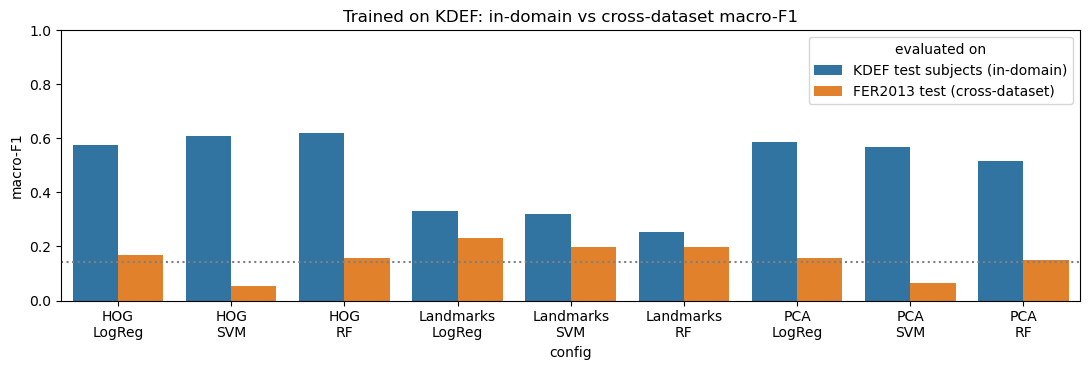

In [8]:
def make_model(feature, clf, **p):
    """
    Build a model pipeline based on feature type and classifier name.
    The pipeline includes preprocessing (scaling, PCA if needed) and the classifier.
    Using make_pipeline ensures consistent preprocessing when training and predicting.
    """
    # If using PCA features, add PCA to the pipeline (reduces dimensions to 95% variance)
    steps = [PCA(n_components=0.95, random_state=RANDOM_STATE)] if feature == "PCA" else []
    if clf == "LogReg":
        # Logistic Regression needs featrue scaling to work well
        steps += [StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE, **p)]
    elif clf == "SVM":
        # Support Vector Machine needs feature scaling
        steps += [StandardScaler(), SVC(kernel="rbf", gamma="scale", random_state=RANDOM_STATE, **p)]
    else:
        # Random Forest doesn't need scaling; it's scale-invariant
        steps += [RandomForestClassifier(n_estimators=300, max_features="sqrt", criterion="entropy",
                                         n_jobs=-1, random_state=RANDOM_STATE, **p)]
    return make_pipeline(*steps) # Combine all steps into a single pipeline
 
def metrics(y, p):
    """Calculate the key evaluation metrics: accuracy, balanced accuracy, and macro-F1."""
    return {"accuracy": accuracy_score(y, p),
            "balanced_accuracy": balanced_accuracy_score(y, p),
            "macro_f1": f1_score(y, p, average="macro")}
 
def evaluate_configs(Kf, Ff):
    """
    Evaluate all model configurations from Task 2:
    - Train on KDEF training set
    - Test on KDEF test set (in-domain performance)
    - Test on FER2013 validation and test sets (cross-domain performance)
    """
    rows, preds, models = [], {}, {}
    for _, r in k2.iterrows(): # Iterate over all configurations from Task 2
        feat, clf = r.feature, r.classifier
        t = time.time()
        # Create and train the model on KDEF training data
        m = make_model(feat, clf, **json.loads(r.params)).fit(Kf[feat][tr], y_tr)
        row = {"feature": feat, "classifier": clf}

        # Evaluate on KDEF test set (in-domain)
        p = m.predict(Kf[feat][te]); preds[(feat, clf, "KDEF")] = p
        row.update({f"KDEF_{k}": v for k, v in metrics(y_te, p).items()})
        
        # Evaluate on FER2013 validation and test sets (cross-domain)
        for s in ["validation", "test"]:
            p = m.predict(Ff[s][feat]); preds[(feat, clf, s)] = p
            row.update({f"FER_{s}_{k}": v for k, v in metrics(FER_Y[s], p).items()})
        rows.append(row); models[(feat, clf)] = m
        print(f"{feat:9s} {clf:6s} KDEF macro-F1 {row['KDEF_macro_f1']:.3f} -> "
              f"FER test macro-F1 {row['FER_test_macro_f1']:.3f}  ({time.time() - t:.0f}s)")
    return pd.DataFrame(rows), preds, models

# Rune the full evaluation 
res, preds, models = evaluate_configs(K_feats, FER_F)
# Calculate the performance drop (in-domain macro-F1 minus cross-domain macro-F1)
# This is a direct measure of how much performance degrades due to domain shift
res["macro_f1_drop"] = res.KDEF_macro_f1 - res.FER_test_macro_f1
res.to_csv(RESULTS / "task3_cross_dataset.csv", index=False) # Save results for reference
 
# A summary table to show the key metrix for all configurations
show = res.set_index(["feature", "classifier"])[
    ["KDEF_accuracy", "KDEF_macro_f1", "FER_test_accuracy", "FER_test_balanced_accuracy",
     "FER_test_macro_f1", "FER_validation_macro_f1", "macro_f1_drop"]]
print(show.round(3).to_string())
# Print the chance level (random guessing) to give context
print("\nChance level for 7 classes: accuracy / macro-F1 about", round(1 / 7, 3))

# Plot a bar chart comparing in-domain vs cross-dataset macro-F1 for each configuration 
res["config"] = res.feature + "\n" + res.classifier
plot_df = res.melt(id_vars="config", value_vars=["KDEF_macro_f1", "FER_test_macro_f1"],
                   var_name="evaluated on", value_name="macro-F1")
plot_df["evaluated on"] = plot_df["evaluated on"].map(
    {"KDEF_macro_f1": "KDEF test subjects (in-domain)", "FER_test_macro_f1": "FER2013 test (cross-dataset)"})
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.barplot(data=plot_df, x="config", y="macro-F1", hue="evaluated on", ax=ax)
ax.axhline(1 / 7, ls=":", c="gray") # Chance level line
ax.set_ylim(0, 1)
ax.set_title("Trained on KDEF: in-domain vs cross-dataset macro-F1")
plt.tight_layout(); plt.savefig(FIGS / "kdef_vs_fer_macro_f1.png", dpi=150); plt.show()

# 5. The selected configuration in detail
### Focus on the best configuration (from Task 2) and analyze its performance in depth.

HOG + LogReg on FER2013 test
              precision    recall  f1-score   support

       Angry      0.182     0.255     0.212       491
     Disgust      0.006     0.018     0.009        55
        Fear      0.141     0.100     0.117       528
       Happy      0.580     0.181     0.276       879
         Sad      0.173     0.362     0.234       594
    Surprise      0.241     0.478     0.321       416
     Neutral      0.000     0.000     0.000       626

    accuracy                          0.210      3589
   macro avg      0.189     0.199     0.167      3589
weighted avg      0.244     0.210     0.190      3589



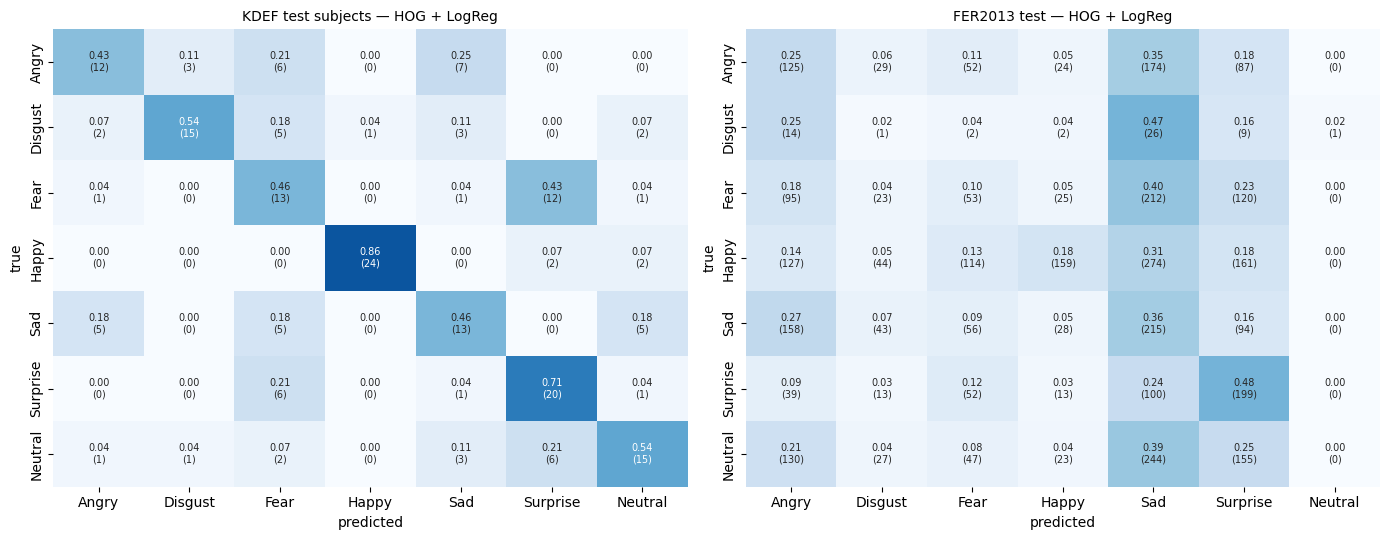

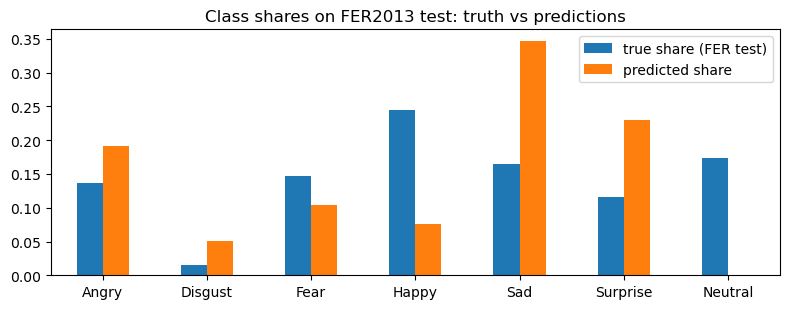

          KDEF F1  FER F1   drop
Angry       0.490   0.212  0.278
Disgust     0.638   0.009  0.630
Fear        0.400   0.117  0.283
Happy       0.906   0.276  0.630
Sad         0.464   0.234  0.230
Surprise    0.588   0.321  0.268
Neutral     0.556   0.000  0.556


In [9]:
bk = (BEST_FEATURE, BEST_CLF) #The best configuration table
y_fer, p_fer = FER_Y["test"], preds[(*bk, "test")] # True labels and predictions on FER test
print(f"{BEST_FEATURE} + {BEST_CLF} on FER2013 test")
# Print a detailed classification report (precision, recall, F1 per class)
print(classification_report(y_fer, p_fer, target_names=EMOTIONS, digits=3, zero_division=0))
 
def plot_cm(y, p, title, ax):
    """
    Plot a confusion matrix with both normalized values (row-wise) and raw counts.
    Normalized values show the percentage of each true class predicted as each class.
    Raw counts show the absolute number of samples.
    """
    cm = confusion_matrix(y, p, labels=range(7))
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1) # Normalize each row
    # Create annotation strings showing both normalized value and count
    annot = np.array([[f"{cmn[i, j]:.2f}\n({cm[i, j]})" for j in range(7)] for i in range(7)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax, annot_kws={"size": 7})
    ax.set_title(title, fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("true")

# Plot confusion matrices side by side: KDEF (in-domain) vs FER (cross-domain)
# Comparing these reveals which emotions are confused in each setting 
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_cm(y_te, preds[(*bk, "KDEF")], f"KDEF test subjects — {BEST_FEATURE} + {BEST_CLF}", axes[0])
plot_cm(y_fer, p_fer, f"FER2013 test — {BEST_FEATURE} + {BEST_CLF}", axes[1])
plt.tight_layout(); plt.savefig(FIGS / "confusion_kdef_vs_fer.png", dpi=150); plt.show()

# Compare the true class distribution with the predicted class distribution on FER test
# This reveals if the model is biased towards predicting certain classes
dist = pd.DataFrame({"true share (FER test)": np.bincount(y_fer, minlength=7) / len(y_fer),
                     "predicted share": np.bincount(p_fer, minlength=7) / len(p_fer)}, index=EMOTIONS)
dist.plot.bar(figsize=(8, 3.2), title="Class shares on FER2013 test: truth vs predictions")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIGS / "prediction_distribution.png", dpi=150); plt.show()

# Compare per-class F1 scores between KDEF and FER
# This shows which emotions transfer well (small drop) and which don't (large drop) 
pc = pd.DataFrame({"KDEF F1": f1_score(y_te, preds[(*bk, "KDEF")], average=None, labels=range(7)),
                   "FER F1": f1_score(y_fer, p_fer, average=None, labels=range(7))}, index=EMOTIONS)
pc["drop"] = pc["KDEF F1"] - pc["FER F1"]
pc.to_csv(RESULTS / "task3_per_class_f1.csv")
print(pc.round(3).to_string())

# 6. Evidence for domain shift
### This section quantitatively measures the domain shift between KDEF and FER2013.Domain shift refers to the difference in data distributions, which causes models to fail.

                      KDEF     FER2013
brightness mean  83.300003  129.100006
brightness std   27.000000   33.700001
contrast mean    40.900002   54.299999
contrast std      6.100000   13.800000


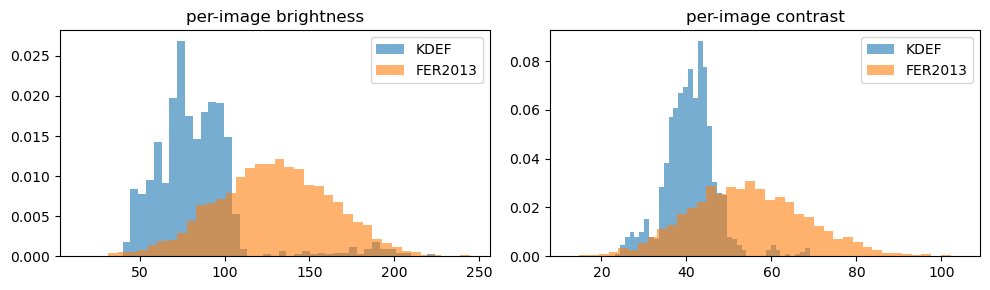

  feature  domain_classifier_accuracy
      HOG                       0.995
Landmarks                       0.881
      PCA                       0.994


In [10]:
def img_stats(x):
    """Calculate per-image mean (brightness) and standard deviation (contrast)."""
    f = x.reshape(len(x), -1).astype(np.float32)
    return f.mean(1), f.std(1)

# Compute brightness and contrast statistics for both datasets 
kb, kc = img_stats(K_imgs); fb, fc = img_stats(FER_IMGS["test"])
# Print summary statistics - large differences indicate strong domain shift
print(pd.DataFrame({"KDEF": [kb.mean(), kb.std(), kc.mean(), kc.std()],
                    "FER2013": [fb.mean(), fb.std(), fc.mean(), fc.std()]},
                   index=["brightness mean", "brightness std", "contrast mean", "contrast std"]).round(1).to_string())

# Histograms of brightness and contrast for both datasets
# Overlapping distributions suggest similar characteristics; separated distributions indicate domain shift 
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (a, b, name) in zip(axes, [(kb, fb, "per-image brightness"), (kc, fc, "per-image contrast")]):
    ax.hist(a, bins=40, density=True, alpha=.6, label="KDEF"); ax.hist(b, bins=40, density=True, alpha=.6, label="FER2013")
    ax.set_title(name); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "brightness_contrast.png", dpi=150); plt.show()
 
# Train a classifier to distinguish between KDEF and FER2013 images
# If the classifier can tell which dataset an image is from with high accuracy, it proves the distributions are different (high domain shift)
rng = np.random.default_rng(RANDOM_STATE)
# Sample an equal number of FER images to balance the two classes
idx = rng.choice(len(FER_Y["test"]), size=len(K_imgs), replace=False)   # balanced: 980 vs 980
dom = [] # List to store results for each feature type
for feat in EXTRACT:
    # Combine both KDEF features (label=0) and FER features (label=1)
    X = np.vstack([K_feats[feat], FER_F["test"][feat][idx]])
    
    d = np.r_[np.zeros(len(K_imgs)), np.ones(len(idx))] # Domain labels: 0=KDEF, 1=FER
    # Train a simple logistic regression classifier using 5-fold cross-validation
    # If accuracy is high (e.g., >0.8), the features can easily distinguish datasets = strong domain shift

    acc = cross_val_score(make_model(feat, "LogReg", C=0.1), X, d, cv=5).mean()
    dom.append({"feature": feat, "domain_classifier_accuracy": acc})
dom = pd.DataFrame(dom)
dom.to_csv(RESULTS / "task3_domain_classifier.csv", index=False)
print(dom.round(3).to_string(index=False))

# 7. Optional adaptation experiment: per-image intensity normalisation
### We test a simple adaptation technique: normalize each image to have zero mean and unit variance. This might help align the feature distributions and reduce domain shift.

In [11]:
def norm_imgs(x):
    """Normalize each image: subtract mean, divide by std, then rescale to 0-255 range."""
    x = x.astype(np.float32)
    m = x.mean(axis=(1, 2), keepdims=True); s = x.std(axis=(1, 2), keepdims=True) + 1e-6
    # Added episilon to avoid div by zero
    return np.clip((x - m) / s * 50 + 128, 0, 255).astype(np.uint8) # Resalce to 0-255

# Apply normalization to both KDEF and FER images and re-extract features 
Kn = norm_imgs(K_imgs)
Kn_feats = {f: EXTRACT[f][1](Kn) for f in EXTRACT} # Features for normalized KDEF
Fn_feats = {s: {f: EXTRACT[f][1](norm_imgs(FER_IMGS[s])) for f in EXTRACT} for s in FER_IMGS} # Features for normalized FER
res_n, preds_n, _ = evaluate_configs(Kn_feats, Fn_feats)

# Compare macro-F1 before and after normalization for each configuration
# This shows whether the adaptation helped or hurt performance 
adapt = res[["feature", "classifier", "FER_test_macro_f1"]].merge(
    res_n[["feature", "classifier", "FER_test_macro_f1"]], on=["feature", "classifier"],
    suffixes=("_direct", "_normalised"))
adapt["change"] = adapt.FER_test_macro_f1_normalised - adapt.FER_test_macro_f1_direct
adapt.to_csv(RESULTS / "task3_normalisation_experiment.csv", index=False)
print(adapt.round(3).to_string(index=False))

HOG       LogReg KDEF macro-F1 0.601 -> FER test macro-F1 0.170  (0s)
HOG       SVM    KDEF macro-F1 0.581 -> FER test macro-F1 0.054  (2s)
HOG       RF     KDEF macro-F1 0.604 -> FER test macro-F1 0.156  (1s)
Landmarks LogReg KDEF macro-F1 0.347 -> FER test macro-F1 0.228  (0s)
Landmarks SVM    KDEF macro-F1 0.342 -> FER test macro-F1 0.198  (0s)
Landmarks RF     KDEF macro-F1 0.259 -> FER test macro-F1 0.203  (1s)
PCA       LogReg KDEF macro-F1 0.675 -> FER test macro-F1 0.162  (0s)
PCA       SVM    KDEF macro-F1 0.583 -> FER test macro-F1 0.035  (1s)
PCA       RF     KDEF macro-F1 0.530 -> FER test macro-F1 0.115  (1s)
  feature classifier  FER_test_macro_f1_direct  FER_test_macro_f1_normalised  change
      HOG     LogReg                     0.167                         0.170   0.003
      HOG        SVM                     0.054                         0.054   0.000
      HOG         RF                     0.157                         0.156  -0.000
Landmarks     LogReg          

# 8. Numbers for the report
### This section gathers all the key numbers that will be needed for the report.

In [12]:
# Get the results for the best configurations
r = res[(res.feature == BEST_FEATURE) & (res.classifier == BEST_CLF)].iloc[0]
print(f"Selected configuration ({SELECT_BY}): {BEST_FEATURE} + {BEST_CLF}")
print(f"  KDEF test (in-domain):  accuracy {r.KDEF_accuracy:.3f}  macro-F1 {r.KDEF_macro_f1:.3f}") # KDEF
print(f"  FER2013 test:           accuracy {r.FER_test_accuracy:.3f}  balanced acc {r.FER_test_balanced_accuracy:.3f}" # FER2013
      f"  macro-F1 {r.FER_test_macro_f1:.3f}")
print(f"  FER2013 validation:     macro-F1 {r.FER_validation_macro_f1:.3f}")

# Calculate and print the mean performance across all classifiers for each feature type
# This helps answer the question "which features transfer best across datasets?" 
by_feat = res.groupby("feature")[["KDEF_macro_f1", "FER_test_macro_f1"]].mean()
# Calculate what % of in-domain performance is retained in cross-domain
by_feat["share_retained"] = by_feat.FER_test_macro_f1 / by_feat.KDEF_macro_f1
print("\nMean over the 3 classifiers, per feature type:")
print(by_feat.round(3).sort_values("FER_test_macro_f1", ascending=False).to_string())

Selected configuration (cv_macro_f1): HOG + LogReg
  KDEF test (in-domain):  accuracy 0.571  macro-F1 0.577
  FER2013 test:           accuracy 0.210  balanced acc 0.199  macro-F1 0.167
  FER2013 validation:     macro-F1 0.174

Mean over the 3 classifiers, per feature type:
           KDEF_macro_f1  FER_test_macro_f1  share_retained
feature                                                    
Landmarks          0.302              0.209           0.691
HOG                0.602              0.126           0.209
PCA                0.557              0.124           0.222
